In [470]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [471]:
#import database / data
conn=sqlite3.connect('customer_churn.db')

sql_query="""
SELECT name
FROM sqlite_master
WHERE type='table'
"""
tables=pd.read_sql(sql_query, conn)

#create dataframe for each table
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created datarame: df_{table_name}")

conn.close()



Created datarame: df_db_customer
Created datarame: df_db_subscription
Created datarame: df_db_support


In [472]:
#data cleaning
df_db_customer.head()


,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [473]:
df_db_customer.info

<bound method DataFrame.info of     customerid        name country          state  gender  \
0   0002-ORFBO      keshav   India    Maharashtra    Male   
1   0003-MKNFE      raghav   India      Karnataka    Male   
2   0004-TLHLJ      lalita   India          Delhi  Female   
3   0011-IGKFF       mohan   India       Nagaland    Male   
4   0013-EXCHZ        mira   India          Delhi  Female   
5   0013-MHZWF       durga     NaN          Delhi   Women   
6   0013-SMEOE        mina   India      Meghalaya  Female   
7   0014-BMAQU       madan   India      Rajasthan    Male   
8   0015-UOCOJ        maya     NaN      Kathmandu   Women   
9   0016-QLJIS       arjun   Nepal      Kathmandu    Male   
10  0017-DINOC       shiva   India    Maharashtra     Men   
11  0017-IUDMW   rangadevi   India      Karnataka  Female   
12  0018-NYROU      chitra     NaN      Telangana  Female   
13  0019-EFAEP        raju   India      Meghalaya  Female   
14  0019-GFNTW      Madhav   India  Uttar Pradesh    

In [474]:
#a.rename columns-name
#b.drop columns-interest and pincode
#c.change data type-dob
#d.data standardization- gender
#e.fix missing values-country

In [475]:
#a. rename col-name
df_db_customer.rename(columns={'name': 'customer_name'},inplace=True)

In [476]:
#b.drop columns-interest and pincode
df_db_customer.drop(columns=['interests', 'pincode'])

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [477]:
#c.change data type-dob
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [478]:
#d.data standardization- gender
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men': 'Male', 'Women': 'Female'})

In [479]:
#e.fix missing values-country
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob,interests,pincode
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07,NaN,None
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01,NaN,None


In [480]:
#country and state-unique value pair
state_country_mapping=df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()
df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [481]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob,interests,pincode


In [482]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [483]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [484]:
date_col=['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col]=df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [485]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [486]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [487]:
df_db_support.drop(columns=['col_1','comment'], inplace=True)

In [488]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [489]:
#3.feature engineering and data analysis

In [490]:
#create a new col using existing col-churn_flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)

In [491]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [492]:
#first fix support table duplicates then merge
df = (df_db_subscription
      .merge(df_db_customer, on='customerid', how='left')
      .merge(df_db_support, on='customerid', how='left'))

In [493]:
df_db_subscription.shape

(21, 12)

In [494]:
df.shape

(23, 22)

In [495]:
df_db_subscription['customerid'].nunique()

21

In [496]:
df_db_customer['customerid'].nunique()

21

In [497]:
df_db_support['customerid'].nunique()

7

In [498]:
df_db_support['customerid'].size

9

In [499]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


In [500]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')   

In [501]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep='last')

In [502]:
df_db_support['customerid'].size

7

In [503]:
#merge df
df=(df_db_subscription
      .merge(df_db_customer, on='customerid', how='left')
      .merge(df_db_support, on='customerid', how='left'))

In [504]:
df.shape

(21, 23)

In [505]:
df.to_csv('churn_analysis.csv', index=False)

In [506]:
#Data analysis

In [507]:
#1.Churn Rate

In [508]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count'],
      dtype='str')

In [509]:
churn_rate = df['churn_flag'].mean()*100
print("churn_rate: ",round(churn_rate,2),"%")

churn_rate:  28.57 %


In [510]:
#2.Retenion Rate
retention_rate = 100 - churn_rate
print("retention_rate: ",round(retention_rate,2),"%")

retention_rate:  71.43 %


In [511]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,country,state,gender,dob,interests,pincode,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,India,Maharashtra,Male,1982-04-12,travel,None,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,India,Karnataka,Male,1995-11-23,NaN,None,2024-08-28,Y,10.0,2.0


In [512]:
#3. churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [513]:
#4 a.churn by state + countof users ---do later
#4 b.Churn by subscription type + sum(revenue) and count of users ---do later

In [514]:
#5.ARPU (Average Revenue Per User) 
arpu = df['monthly_charges'].mean()
print("ARPU: ", round(arpu, 2))

ARPU:  18.85


In [515]:
#calculate customer age  ---dolater

In [516]:
#6. avg customer tenure
# count of days users has used our servise:cancellation date else current date
# 1. Ensure both columns are datetime objects
df['cancellation_date'] = pd.to_datetime(df['cancellation_date'])
df['subscription_start_date'] = pd.to_datetime(df['subscription_start_date'])

# 2. Assign the calculation to 'tenure_days' instead of 'cancellation_date'
today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Average tenure (in days): ", round(avg_tenure, 0))

Average tenure (in days):  1560.0


In [517]:
#Revenue at risk-revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag'] == 1, 'monthly_charges'].sum()
print("Revenue at risk: ", revenue_at_risk)

Revenue at risk:  73.94


In [518]:
#8. Esclation Rate
escalation_rate = (df['escalations']=='Y').mean()*100
print("Escalation Rate: ", round(escalation_rate, 2), "%")

Escalation Rate:  19.05 %


In [519]:
#9. Avg Complaint Per User
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Average Complaints Per User: ", round(avg_complaints, 2))

Average Complaints Per User:  0.43


In [520]:
#10. Correlation Escation VS churn
df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0) #encoding string to int type
corr_df=df[['escalations','churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between Escalation and Churn: ", round(correlation, 2))

Correlation between Escalation and Churn:  0.77


In [521]:
#11. churn risk-crate a new col using existing col-churn_flag
conditions=[
    (df['churn_score'] <50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),
    (df['churn_score'] >= 70)
]
choises=['Low Risk','Medium Risk','High Risk']
df['churn_risk'] = np.select(conditions, choises, default='Unknown')

In [522]:
df[['churn_risk','churn_score']].tail()

,churn_risk,churn_score
16,Medium Risk,62
17,Low Risk,27
18,High Risk,99
19,Low Risk,7
20,Low Risk,47


In [523]:
#4. visualization using matplotlib

In [524]:
df_visual=df.copy()

In [525]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count', 'tenure_days', 'churn_risk'],
      dtype='str')

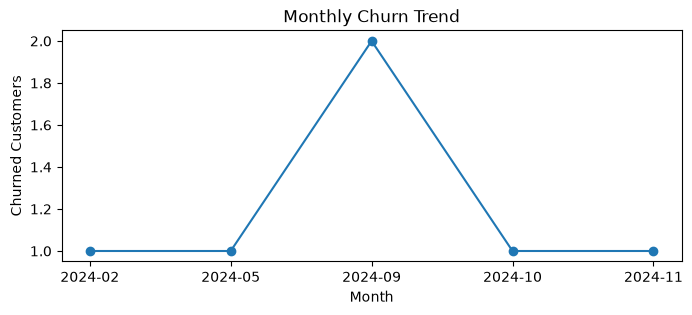

In [526]:
#4.1 Monthly churn Trend(time series KPI)
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')  
churn_trend = df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, marker='o')

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

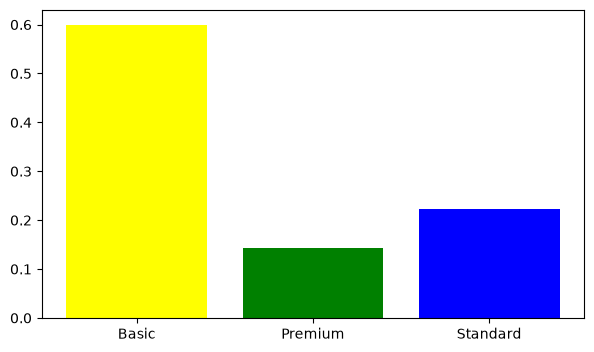

In [527]:
#4.2 Churn by Plan Type (Bar Chart)
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()
colors=['yellow', 'green', 'blue']  # Specify colors for each bar
plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color=colors)
plt.show()

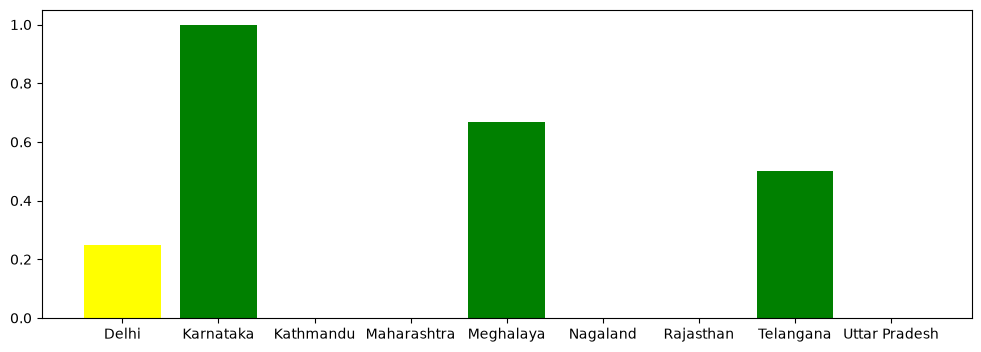

In [528]:
#4.3 Churn by State 
churn_plan = df_visual.groupby('state')['churn_flag'].mean()
colors=['yellow', 'green', 'blue']  # Specify colors for each bar
plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color=colors)
plt.show()

In [529]:
#visualization using seaborn

In [530]:
#encording-convert str to numeric so that we can find corr between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [531]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']] 

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low Risk,0
1,Premium,Annual,91,1,High Risk,1
2,Basic,Monthly,34,0,Low Risk,0
3,Premium,Annual,8,0,Low Risk,0
4,Standard,Monthly,88,1,High Risk,1
5,Standard,Annual,22,0,Low Risk,0
6,Basic,Monthly,79,1,High Risk,0
7,Premium,Annual,5,0,Low Risk,0
8,Standard,Monthly,34,0,Low Risk,0
9,Basic,Annual,41,0,Low Risk,0


In [532]:
import warnings
warnings.filterwarnings("ignore")

In [533]:
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']] 
categorical_cols=['plan_type', 'contract_type', 'churn_risk']
for col in categorical_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

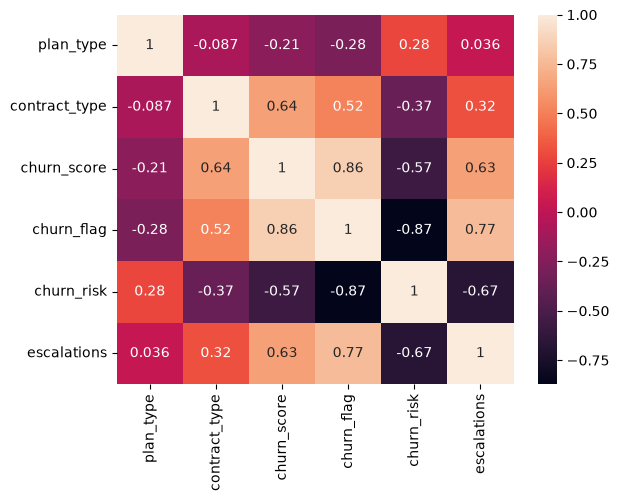

In [534]:
#heatmap(correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

In [535]:
df_visual['churn_risk'].unique()

<StringArray>
['Low Risk', 'High Risk', 'Medium Risk']
Length: 3, dtype: str

In [536]:
#correct method of encoding- based on priority
df_encoded=df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']]

order_mappings = {
    'plan_type': ['Basic', 'Standard', 'Premium'],
    'contract_type': ['Monthly', 'Annual'],
    'churn_risk': ['Low Risk', 'Medium Risk', 'High Risk']
}
for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [537]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low Risk,0
1,Premium,Annual,91,1,High Risk,1
2,Basic,Monthly,34,0,Low Risk,0
3,Premium,Annual,8,0,Low Risk,0
4,Standard,Monthly,88,1,High Risk,1


In [538]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,1
2,0,0,34,0,0,0
3,2,1,8,0,0,0
4,1,0,88,1,2,1


<Axes: >

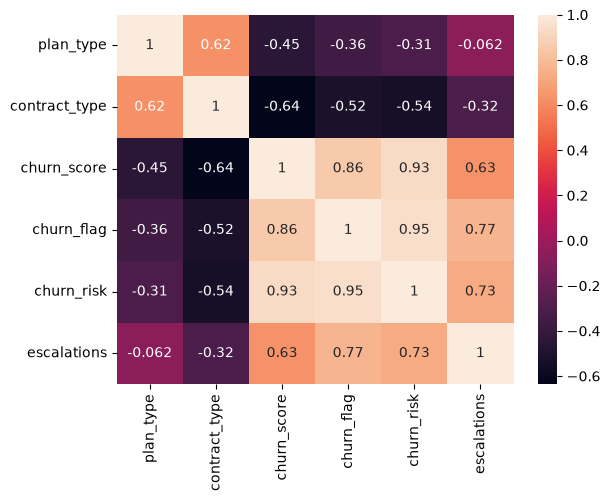

In [539]:
#heatmap(correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

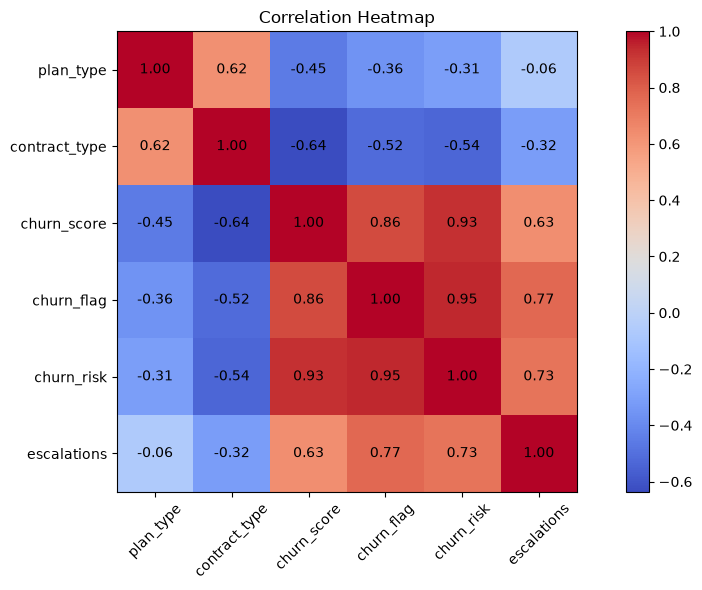

In [540]:
# Heatmap Using Matplotlib - difficult to plot it[cite: 17]

corr_matrix = df_encoded.corr() # Correlation matrix[cite: 17]

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure[cite: 17]

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap[cite: 17]

fig.colorbar(cax) # Add colorbar[cite: 17]

# Axis Labels[cite: 17]
ax.set_xticks(np.arange(len(corr_matrix.columns))) #[cite: 17]
ax.set_yticks(np.arange(len(corr_matrix.columns))) #[cite: 17]

ax.set_xticklabels(corr_matrix.columns, rotation=45) #[cite: 17]
ax.set_yticklabels(corr_matrix.columns) #[cite: 17]

# Annotate values inside cells[cite: 17, 18]
for i in range(len(corr_matrix.columns)): #[cite: 17, 18]
    for j in range(len(corr_matrix.columns)): #[cite: 17, 18]
        ax.text( #[cite: 17, 18]
            j, #[cite: 18]
            i, #[cite: 18]
            f"{corr_matrix.iloc[i, j]:.2f}", #[cite: 18]
            ha='center', #[cite: 18]
            va='center' #[cite: 18]
        ) #[cite: 18]

plt.title('Correlation Heatmap') # Title[cite: 18]

plt.tight_layout() #[cite: 18]
plt.show() #[cite: 18]

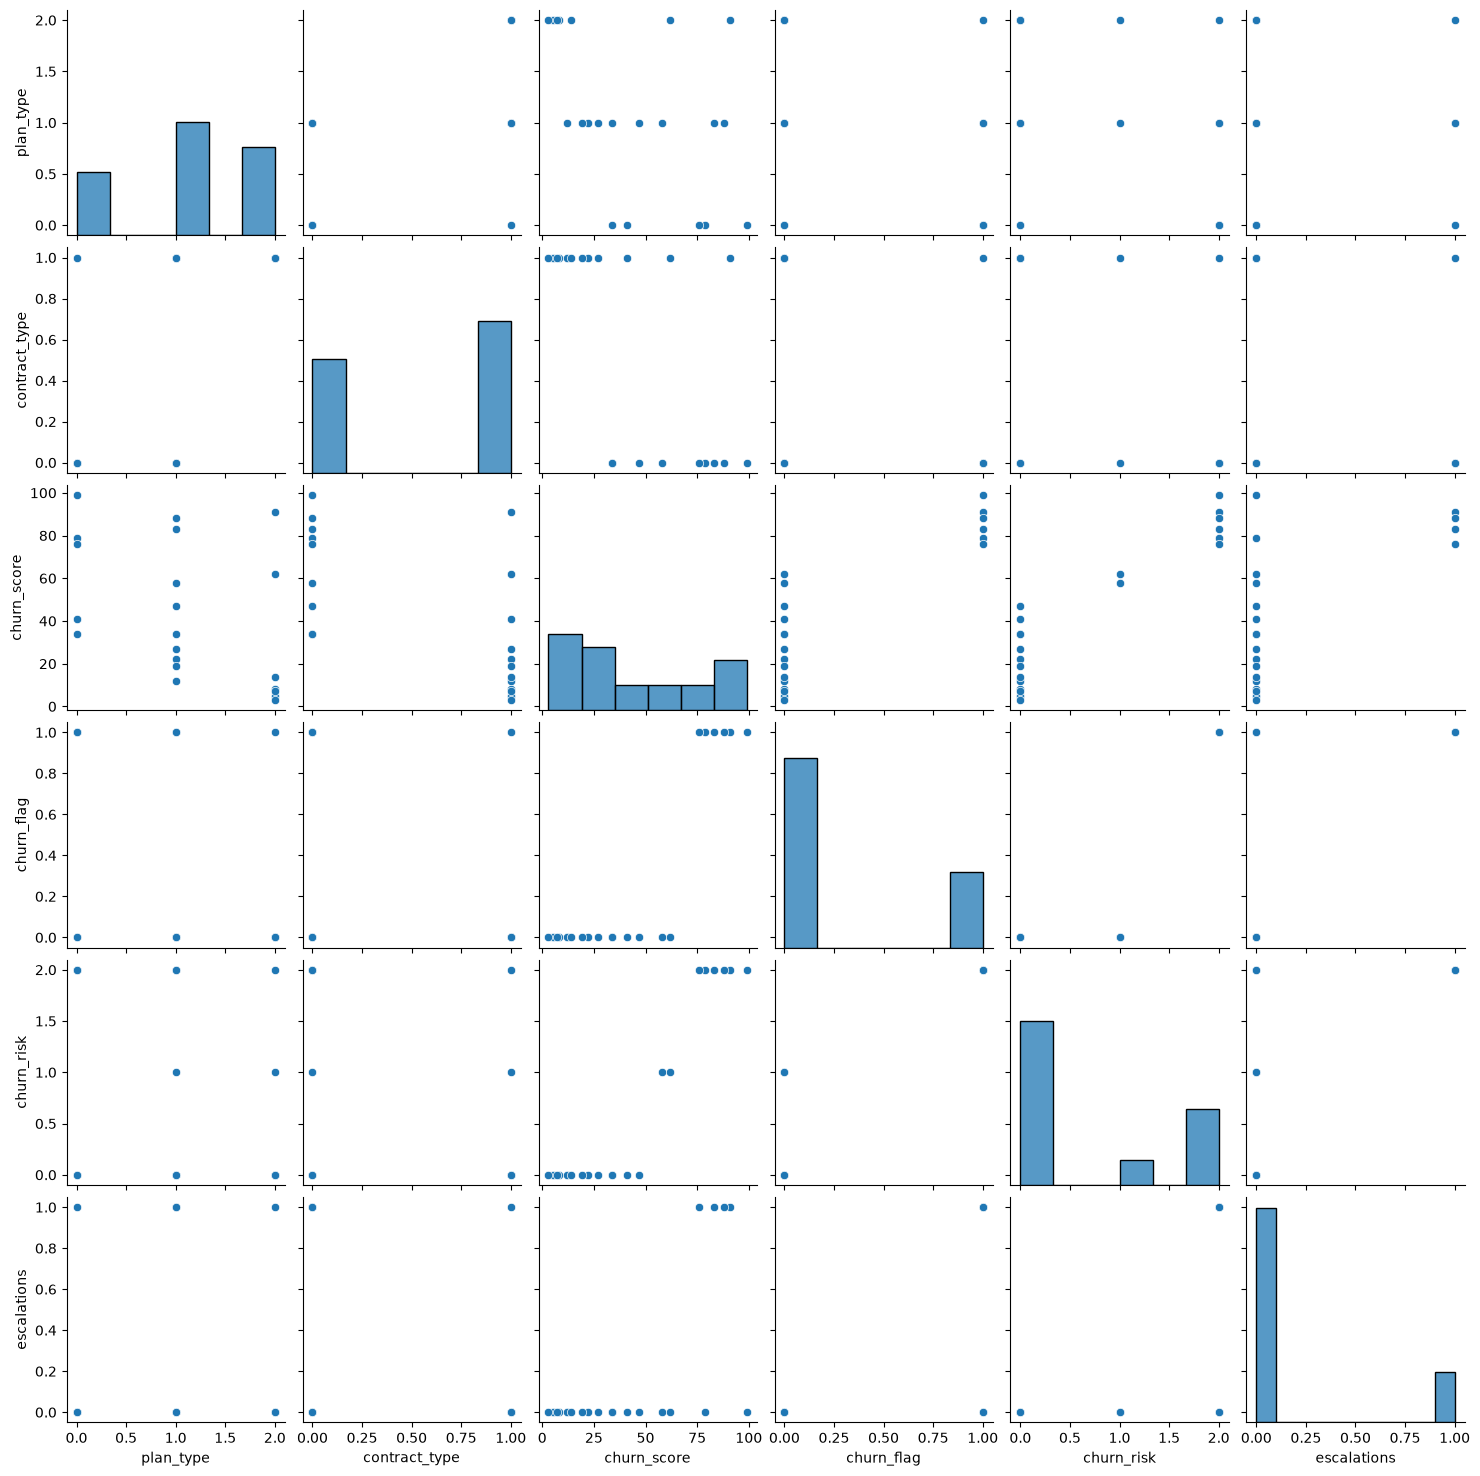

In [541]:
#pairplot-relationship in a data set
sns.pairplot(df_encoded)

In [542]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

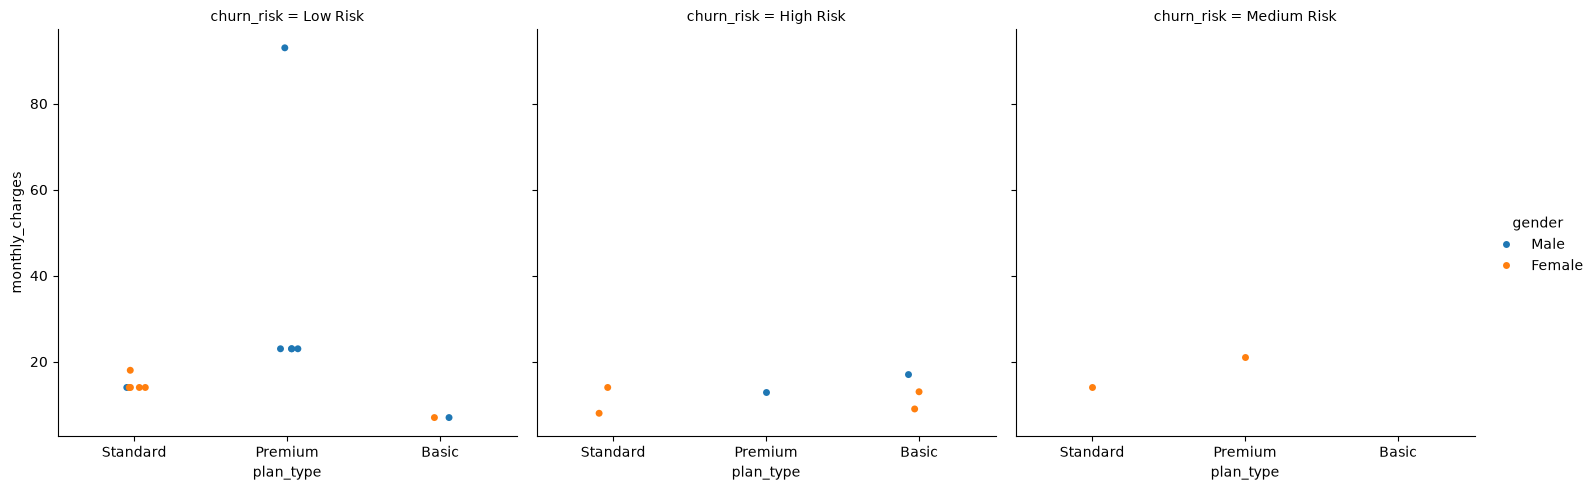

In [543]:
#catplot-facegrid plot
sns.catplot(data=df_visual, 
            x='plan_type', 
            y='monthly_charges', 
            hue='gender', 
            col='churn_risk')

In [544]:
#pivot table
pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc='mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [545]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'interests', 'pincode', 'complaint_date', 'escalations', 'csat_score',
       'complaint_count', 'tenure_days', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [546]:
pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges','customerid','churn_flag'],
    aggfunc={
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag':'mean'

    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [547]:
#working with SQL in python(pandas)

In [566]:
#create bd in sql
conn=sqlite3.connect('test_database.sqlite')
#table details
conn.execute("CREATE TABLE IF NOT EXISTS users(first_name TEXT, country TEXT, budget INTEGER)")
#commit and save
conn.commit()

In [563]:
#insert data
cursor=conn.cursor()

#write sql query to insert records in sql table
cursor.execute(
    """
        INSERT INTO users VALUES
        ('Madhav','india','5000'),
        ('Rishabh','Germany','2500'),
        ('Vishakha','India','3500')
        
    """
)

#commit and save
conn.commit()
print("Data Inserted successfully")


Data Inserted successfully


In [559]:
#check inserted data in table
conn=sqlite3.connect('test_database.sqlite')
query="""SELECT*FROM users  """

df_results=pd.read_sql(query,conn)
df_results.head()

,first_name,country,buget
0,Madhav,india,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500
3,Madhav,india,5000
4,Rishabh,Germany,2500


In [564]:
# aggregation
query = """
    SELECT country, SUM(budget) as total_budget
    FROM users
    GROUP BY country
"""

df_agg = pd.read_sql(query, conn)
df_agg

,country,total_budget
0,Germany,5000
1,India,7000
2,india,10000


In [561]:
conn.execute("DROP TABLE IF EXISTS users")
conn.execute("CREATE TABLE users(first_name TEXT, country TEXT, budget INTEGER)")
conn.commit()

In [569]:
#always close the conn with bd once the task is over
conn.close()